In [ ]:
#Buddy 9
#ACEBEDO, JOANA PAULA -Visuals of key observations from the dataset
#CUIZON, JHADE - Visuals of key observations from the dataset
#TORRES, ALEZANDRA ZANDY - N/A
#SARATAN, GABRIEL SJOERD - N/A
#LA ROSA, MATT ANGELO - Cleaning, Augmentation, Imputation, Encoding, General Desciptive Statistics, Visuals of key observations from the dataset

In [117]:
import os
import kagglehub
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px

path = kagglehub.dataset_download("aquilarozeusazores/dpwh-flood-control-projects-philippines")
df =pd.read_csv(os.path.join(path, os.listdir(path)[0]))

#Importing to load external libraries and packages like pandas, numpy, matplot.lib and plotly into our workspace to use their functions and tools.
#Also, the DPWH flood control project is also imported from kagglehub

Using Colab cache for faster access to the 'dpwh-flood-control-projects-philippines' dataset.


In [ ]:
#Preprocessing

In [ ]:
df.head()
#head() to print the first five rows of the dataset

,MainIsland,Region,Province,LegislativeDistrict,Municipality,DistrictEngineeringOffice,ProjectId,ProjectName,TypeOfWork,FundingYear,...,ContractCost,ActualCompletionDate,Contractor,ContractorCount,StartDate,ProjectLatitude,ProjectLongitude,ProvincialCapital,ProvincialCapitalLatitude,ProvincialCapitalLongitude
0,Luzon,Cordillera Administrative Region,Apayao,APAYAO (LEGISLATIVE DISTRICT),NaN,Apayao 2nd District Engineering Office,P00526268LZ,Construction of Poblacion Flood Control Struct...,Construction of Flood Mitigation Structure,2021,...,92692943.8,2022-10-03,ASC CONSTRUCTION & CONCRETE PRODUCTS,1,2021-03-18,18.25091,121.047570,Kabugao,18.0215,121.1716
1,Luzon,Cordillera Administrative Region,Apayao,APAYAO (LEGISLATIVE DISTRICT),NaN,Apayao 2nd District Engineering Office,P00526368LZ,Construction of Cabicungan Flood Control Struc...,Construction of Flood Mitigation Structure,2021,...,47521251.3,2022-11-24,ASC CONSTRUCTION & CONCRETE PRODUCTS,1,2021-12-01,18.51180,121.078290,Kabugao,18.0215,121.1716
2,Luzon,Cordillera Administrative Region,Apayao,APAYAO (LEGISLATIVE DISTRICT),NaN,Apayao 2nd District Engineering Office,P00526369LZ,Construction of Sipa-San Mariano Flood Control...,Construction of Flood Mitigation Structure,2021,...,45942583.67,2022-11-28,ASC CONSTRUCTION & CONCRETE PRODUCTS,1,2021-12-01,18.27023,121.420220,Kabugao,18.0215,121.1716
3,Luzon,Cordillera Administrative Region,Apayao,APAYAO (LEGISLATIVE DISTRICT),NaN,Apayao 2nd District Engineering Office,P00561270LZ,Construction of Sta. Filomena Floodway/ Flood ...,Construction of Flood Mitigation Structure,2021,...,9900000,2022-12-15,ASC CONSTRUCTION & CONCRETE PRODUCTS,1,2021-12-01,18.53566,121.080200,Kabugao,18.0215,121.1716
4,Luzon,Cordillera Administrative Region,Apayao,APAYAO (LEGISLATIVE DISTRICT),NaN,Apayao 2nd District Engineering Office,P00561652LZ,"Construction of Sinigpit Flood Control, Calana...",Construction of Flood Mitigation Structure,2021,...,4950000,2022-09-23,ALEPHNORTH PEAK CONSTRUCTION AND DEVELOPMENT CO.,1,2021-12-01,18.52723,121.096812,Kabugao,18.0215,121.1716


In [ ]:
df.info()
#info() to determine the number of missing values and data type per column

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9855 entries, 0 to 9854
Data columns (total 22 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   MainIsland                  9855 non-null   object 
 1   Region                      9855 non-null   object 
 2   Province                    9855 non-null   object 
 3   LegislativeDistrict         9855 non-null   object 
 4   Municipality                9189 non-null   object 
 5   DistrictEngineeringOffice   9855 non-null   object 
 6   ProjectId                   9855 non-null   object 
 7   ProjectName                 9855 non-null   object 
 8   TypeOfWork                  9855 non-null   object 
 9   FundingYear                 9855 non-null   int64  
 10  ContractId                  9855 non-null   object 
 11  ApprovedBudgetForContract   9855 non-null   object 
 12  ContractCost                9855 non-null   object 
 13  ActualCompletionDate        9855 

In [ ]:
df.isnull().sum()
#counting the number of missing values per column

,0
MainIsland,0
Region,0
Province,0
LegislativeDistrict,0
Municipality,666
DistrictEngineeringOffice,0
ProjectId,0
ProjectName,0
TypeOfWork,0
FundingYear,0


In [ ]:
print("Duplicates:", df.duplicated().sum())
#counting the duplicated rows

Duplicates: 0


In [122]:
df = df.drop(columns=["Municipality"])

#Dropping the municipality column since it has a large number of missing values.
#Since there are multiple municipalities in each province that are unique from one another and hence, data imputation to fill these missing municipalities can't be applied.

In [123]:
df["ApprovedBudgetForContract"] = pd.to_numeric(df["ApprovedBudgetForContract"], errors="coerce")
df["ApprovedBudgetForContract"] = df["ApprovedBudgetForContract"].fillna(df["ApprovedBudgetForContract"].median())

#Since the column "ApprovedBudgetForContract" was a string data type, numeric values were converted to float to perform arithmetic operation while non-numeric values were coerced into missing values.
#To fill the missing values, imputation was performed using the median since it is resistant to outliers unlike the mean.

In [124]:
df["ContractCost"] = pd.to_numeric(df["ContractCost"], errors="coerce")
df["ContractCost"] = df["ContractCost"].fillna(df["ContractCost"].median())

#Since the column "ContractCost" was a string data type, numeric values were converted to float to perform arithmetic operation while non-numeric values were coerced into missing values.
#To fill the missing values, imputation was performed using the median since it is resistant to outliers unlike the mean.

In [125]:
df["StartDate"] = pd.to_datetime(df["StartDate"], format="%Y-%m-%d", errors="coerce")
df["ActualCompletionDate"] = pd.to_datetime(df["ActualCompletionDate"], format="%Y-%m-%d", errors="coerce")

#The columns "StartDate" and "ActualCompletionDate" were stored as a string data type, and hence they were converted to datetime to perform arithmetic operation

In [126]:
df["BudgetDiscrepancy"] = df["ContractCost"] - df["ApprovedBudgetForContract"]
df["BudgetDiscrepancyPct"] = df["BudgetDiscrepancy"] / df["ApprovedBudgetForContract"] * 100
df["hasBudgetDiscrepancy"] = np.where(df["BudgetDiscrepancy"] != 0, 1, 0)
df["ProjectDuration"] = (df["ActualCompletionDate"] - df["StartDate"]).dt.days

#New column "BudgetDiscrepancy" to determine the difference between "ContractCost" and "ApprovedBudgetForContract", and the column "hasBudgetDiscrepancy" to mark each project that has a budget discrepancy which would be used later in the analysis.
#"ProjectDuration" is also computed to determine the relationship between the "ApprovedBudgetForContract" and "ProjectDuration".

In [127]:
df.head()
#printing the first five rows of the cleaned dataset

,MainIsland,Region,Province,LegislativeDistrict,DistrictEngineeringOffice,ProjectId,ProjectName,TypeOfWork,FundingYear,ContractId,...,StartDate,ProjectLatitude,ProjectLongitude,ProvincialCapital,ProvincialCapitalLatitude,ProvincialCapitalLongitude,BudgetDiscrepancy,BudgetDiscrepancyPct,hasBudgetDiscrepancy,ProjectDuration
0,Luzon,Cordillera Administrative Region,Apayao,APAYAO (LEGISLATIVE DISTRICT),Apayao 2nd District Engineering Office,P00526268LZ,Construction of Poblacion Flood Control Struct...,Construction of Flood Mitigation Structure,2021,21PC0018,...,2021-03-18,18.25091,121.047570,Kabugao,18.0215,121.1716,-3807056.20,-3.945136,1,564
1,Luzon,Cordillera Administrative Region,Apayao,APAYAO (LEGISLATIVE DISTRICT),Apayao 2nd District Engineering Office,P00526368LZ,Construction of Cabicungan Flood Control Struc...,Construction of Flood Mitigation Structure,2021,21PC0019,...,2021-12-01,18.51180,121.078290,Kabugao,18.0215,121.1716,-1478748.70,-3.017854,1,358
2,Luzon,Cordillera Administrative Region,Apayao,APAYAO (LEGISLATIVE DISTRICT),Apayao 2nd District Engineering Office,P00526369LZ,Construction of Sipa-San Mariano Flood Control...,Construction of Flood Mitigation Structure,2021,21PC0010,...,2021-12-01,18.27023,121.420220,Kabugao,18.0215,121.1716,-1480596.33,-3.122094,1,362
3,Luzon,Cordillera Administrative Region,Apayao,APAYAO (LEGISLATIVE DISTRICT),Apayao 2nd District Engineering Office,P00561270LZ,Construction of Sta. Filomena Floodway/ Flood ...,Construction of Flood Mitigation Structure,2021,21PC0067,...,2021-12-01,18.53566,121.080200,Kabugao,18.0215,121.1716,0.00,0.000000,0,379
4,Luzon,Cordillera Administrative Region,Apayao,APAYAO (LEGISLATIVE DISTRICT),Apayao 2nd District Engineering Office,P00561652LZ,"Construction of Sinigpit Flood Control, Calana...",Construction of Flood Mitigation Structure,2021,21PC0034,...,2021-12-01,18.52723,121.096812,Kabugao,18.0215,121.1716,0.00,0.000000,0,296


In [ ]:
#Studying the Dataset

In [140]:
print(df.describe())
#printing the summary measures of each column

       FundingYear  ApprovedBudgetForContract  ContractCost  \
count  9855.000000               9.855000e+03  9.855000e+03   
mean   2022.766210               5.658783e+07  5.550601e+07   
min    2018.000000               1.158000e+06  1.154359e+06   
25%    2022.000000               2.895000e+07  2.450000e+07   
50%    2023.000000               4.900000e+07  4.899158e+07   
75%    2023.000000               8.684993e+07  8.498584e+07   
max    2025.000000               3.105763e+08  2.895000e+08   
std       0.918505               3.978898e+07  3.944417e+07   

                ActualCompletionDate  ContractorCount  \
count                           9855      9855.000000   
mean   2023-09-26 07:49:19.999999744         1.136986   
min              2022-07-01 00:00:00         1.000000   
25%              2022-12-24 00:00:00         1.000000   
50%              2023-09-23 00:00:00         1.000000   
75%              2024-05-24 00:00:00         1.000000   
max              2025-05-30 00:00

In [139]:
contractors = (df["Contractor"].astype(str).str.split("/").explode().str.strip())
contractor_counts = contractors.value_counts()
print(contractor_counts.head(10))
#counting the number projects per contractor to determine which contractor has the most number of projects

Contractor
LEGACY CONSTRUCTION CORPORATION (FORMERLY: LEGACY CONSTRUCTION)             133
ALPHA & OMEGA GEN. CONTRACTOR & DEVELOPMENT CORP.                           105
ST. TIMOTHY CONSTRUCTION CORPORATION                                        105
QM BUILDERS                                                                  96
EGB CONSTRUCTION CORPORATION (FORMERLY: EGB CONSTRUCTION)                    95
TOPNOTCH CATALYST BUILDERS INC.                                              88
CENTERWAYS CONSTRUCTION AND DEVELOPMENT INC.                                 87
SUNWEST, INC. (FORMERLY: SUNWEST CONSTRUCTION & DEVELOPMENT CORPORATION)     79
HI-TONE CONSTRUCTION & DEVELOPMENT CORP. (FORMERLY                           61
ROYAL CROWN MONARCH CONSTRUCTION & SUPPLIES CORP.                            60
Name: count, dtype: int64


In [148]:
df.groupby("FundingYear")["ApprovedBudgetForContract"].sum().to_frame().style.format({"ApprovedBudgetForContract": "₱{:,.2f}"})
#getting the total approved budget for contract per year to determine which year has the most approved budget and examine the trend

,ApprovedBudgetForContract
FundingYear,
2018,"₱755,318,255.52"
2019,"₱343,529,939.37"
2020,"₱2,394,654,149.90"
2021,"₱31,123,658,263.15"
2022,"₱168,862,472,755.26"
2023,"₱206,910,156,165.90"
2024,"₱145,815,173,051.52"
2025,"₱1,468,087,365.72"


In [142]:
df.groupby("MainIsland")["ApprovedBudgetForContract"].sum().to_frame().style.format({"ApprovedBudgetForContract": "₱{:,.2f}"})
#getting the total approved budget for contract per main island to determine which island has the most approved budget

,ApprovedBudgetForContract
MainIsland,
Luzon,"₱376,889,216,766.23"
Mindanao,"₱95,481,812,700.35"
Visayas,"₱85,302,020,479.76"


In [141]:
df.groupby("Region")["ApprovedBudgetForContract"].sum().to_frame().style.format({"ApprovedBudgetForContract": "₱{:,.2f}"})
#getting the total approved budget for contract per region to determine which region has the most approved budget

,ApprovedBudgetForContract
Region,
Cordillera Administrative Region,"₱17,621,323,967.03"
National Capital Region,"₱53,555,325,096.73"
Region I,"₱39,923,431,092.20"
Region II,"₱36,531,130,776.51"
Region III,"₱98,581,208,015.94"
Region IV-A,"₱41,111,973,561.52"
Region IV-B,"₱35,595,100,533.93"
Region IX,"₱6,057,765,455.12"
Region V,"₱53,972,941,222.37"


In [157]:
df.groupby("FundingYear")["hasBudgetDiscrepancy"].sum()

#getting the total number of projects that has a budget discrepancy per year to determine which year has the most budget discrepancies
#Note: The "hasBudgetDiscrepancy" variable serves as an audit risk indicator to flag potential procurement irregularities and administrative red flags rather than conclusive proof of corruption

,hasBudgetDiscrepancy
FundingYear,
2018,7
2019,3
2020,21
2021,492
2022,2589
2023,2962
2024,1980
2025,32


In [158]:
discrepancyrate_fundingyear = df.groupby("FundingYear")["hasBudgetDiscrepancy"].mean().to_frame()
display(discrepancyrate_fundingyear.style.format({"hasBudgetDiscrepancy": "{:.2%}"}))

#getting the discrepancy rate per year to determine which year has the most discrepancy rate

,hasBudgetDiscrepancy
FundingYear,
2018,100.00%
2019,100.00%
2020,58.33%
2021,79.48%
2022,77.63%
2023,85.46%
2024,84.11%
2025,91.43%


In [143]:
df.groupby("MainIsland")["hasBudgetDiscrepancy"].sum()

#getting the total number of projects that has a budget discrepancy per main island to determine which island has the most budget discrepancies

,hasBudgetDiscrepancy
MainIsland,
Luzon,5716
Mindanao,1118
Visayas,1252


In [156]:
discrepancyrate_mainisland = df.groupby("MainIsland")["hasBudgetDiscrepancy"].mean().to_frame()
display(discrepancyrate_mainisland.style.format({"hasBudgetDiscrepancy": "{:.2%}"}))

#getting the discrepancy rate per main island to determine which island has the most discrepancy rate

,hasBudgetDiscrepancy
MainIsland,
Luzon,85.34%
Mindanao,73.55%
Visayas,76.48%


In [146]:
df.groupby("Region")["hasBudgetDiscrepancy"].sum()

#getting the total number of projects that has a budget discrepancy per region to determine which region has the most budget discrepancies

,hasBudgetDiscrepancy
Region,
Cordillera Administrative Region,292
National Capital Region,1017
Region I,743
Region II,443
Region III,1481
Region IV-A,580
Region IV-B,494
Region IX,118
Region V,667


In [154]:
discrepancyrate_region = df.groupby("Region")["hasBudgetDiscrepancy"].mean().to_frame()
display(discrepancyrate_region.style.format({"hasBudgetDiscrepancy": "{:.2%}"}))

#getting the discrepancy rate per region to determine which region has the most discrepancy rate

,hasBudgetDiscrepancy
Region,
Cordillera Administrative Region,82.95%
National Capital Region,96.12%
Region I,87.31%
Region II,70.54%
Region III,91.59%
Region IV-A,69.96%
Region IV-B,99.20%
Region IX,88.72%
Region V,77.02%


In [ ]:
#Plotting

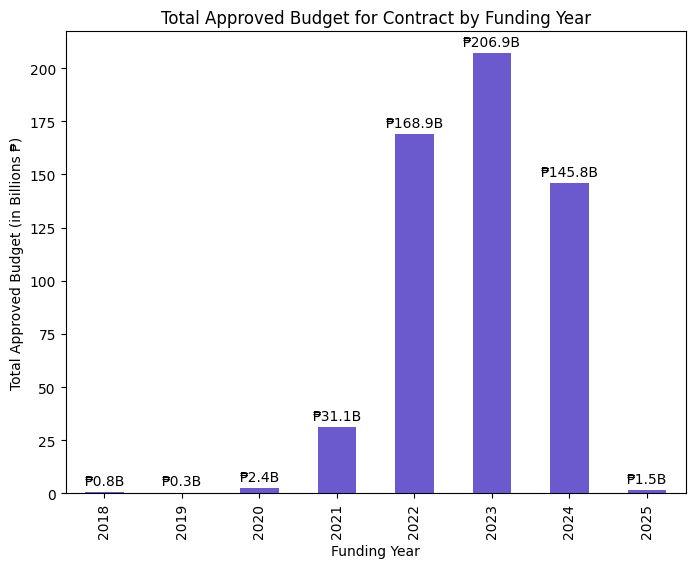

In [193]:
fig, ax = plt.subplots(figsize=(8, 6))

year_budget = df.groupby("FundingYear")["ApprovedBudgetForContract"].sum() / 1e9
year_budget.plot(kind="bar", ax=ax, color="slateblue")
ax.bar_label(ax.containers[0], fmt='₱%.1fB', padding=3)
ax.set_title("Total Approved Budget for Contract by Funding Year")
ax.set_xlabel("Funding Year")
ax.set_ylabel("Total Approved Budget (in Billions ₱)")

plt.show()

#Bar plot to compare the total approved budget per year and to visiualize the differences in approved budget per year.
#Based on the bar plot, 2023 has the most approved budget since this is the first year of the current administration.

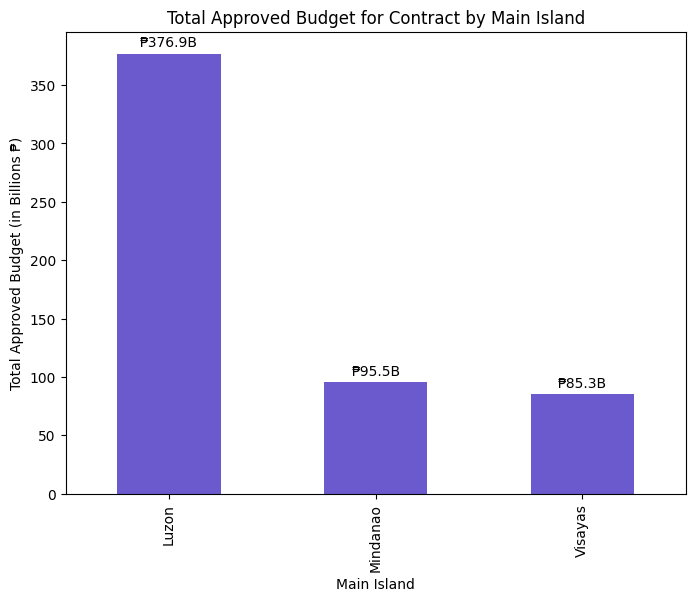

In [192]:
fig, ax = plt.subplots(figsize=(8, 6))

island_budget = df.groupby("MainIsland")["ApprovedBudgetForContract"].sum() / 1e9
island_budget.plot(kind="bar", ax=ax, color="slateblue")
ax.bar_label(ax.containers[0], fmt='₱%.1fB', padding=3)
ax.set_title("Total Approved Budget for Contract by Main Island")
ax.set_xlabel("Main Island")
ax.set_ylabel("Total Approved Budget (in Billions ₱)")

plt.show()

#Bar plot to compare the total approved budget per main island and to easily spot which island has the most approved budget.
#Based on the bar plot, Luzon has the most approved budget since this island is the most flood-prone island and has the largest landmass that is occasionally hit by typhoons.

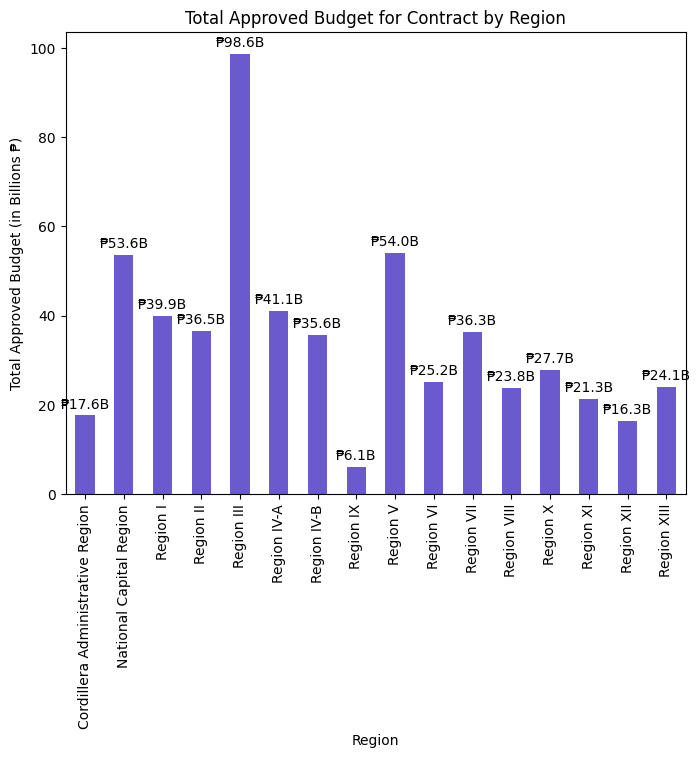

In [194]:
fig, ax = plt.subplots(figsize=(8, 6))

region_budget = df.groupby("Region")["ApprovedBudgetForContract"].sum() / 1e9
region_budget.plot(kind="bar", ax=ax, color="slateblue")
ax.bar_label(ax.containers[0], fmt='₱%.1fB', padding=3)
ax.set_title("Total Approved Budget for Contract by Region")
ax.set_xlabel("Region")
ax.set_ylabel("Total Approved Budget (in Billions ₱)")

plt.show()

#Bar plot to compare the total approved budget per region and to visiualize the differences in approved budget per region
#Based on the bar plot, Region III has the highest approved budget since this is the most flood-prone and exposed region in the Philippines.

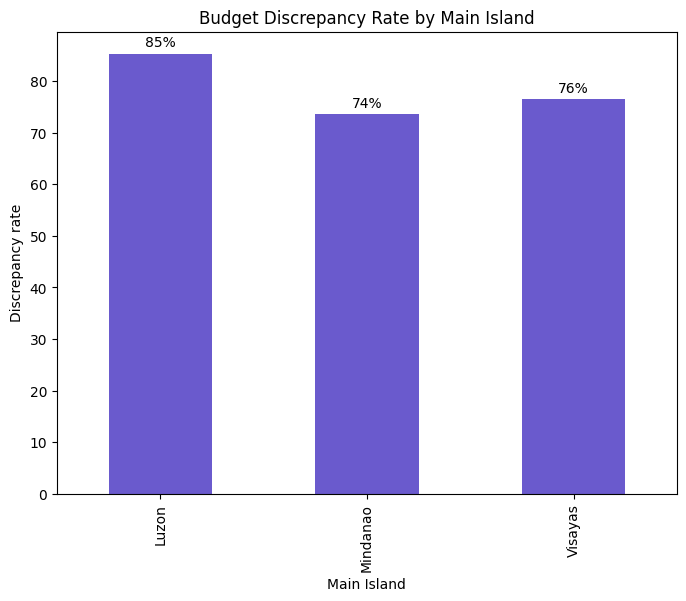

In [189]:
fig, ax = plt.subplots(figsize=(8, 6))

mainisland_discrepancyrate = df.groupby("MainIsland")["hasBudgetDiscrepancy"].mean() * 100
mainisland_discrepancyrate.plot(kind="bar", ax=ax, color="slateblue")
ax.bar_label(ax.containers[0], fmt='%.0f%%', padding=3)
ax.set_title("Budget Discrepancy Rate by Main Island")
ax.set_xlabel("Main Island")
ax.set_ylabel("Discrepancy rate")

plt.show()

#Bar plot to compare the budget discrepancy rate per main island and to visiualize the differences in budget discrepancy rate per main island.
#Based on the bar plot, Luzon has the highest discrepancy rate since this island has the highest number of projects, highest approved budget and the hotspot of the recent flood control scandal particularly Bulacan, NCR, and Mindoro.


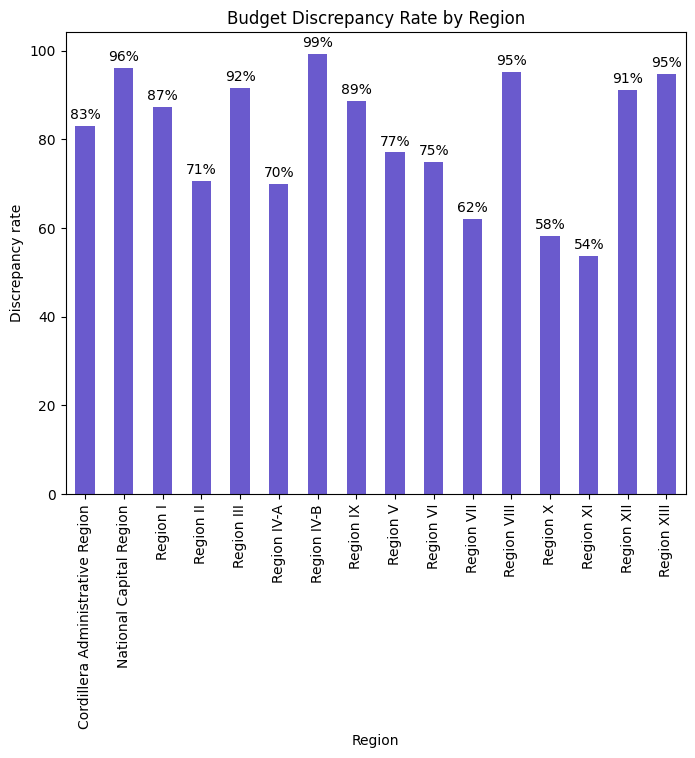

In [188]:
fig, ax = plt.subplots(figsize=(8, 6))

region_discrepancyrate = df.groupby("Region")["hasBudgetDiscrepancy"].mean() * 100
region_discrepancyrate.plot(kind="bar", ax=ax, color="slateblue")
ax.bar_label(ax.containers[0], fmt='%.0f%%', padding=3)
ax.set_title("Budget Discrepancy Rate by Region")
ax.set_xlabel("Region")
ax.set_ylabel("Discrepancy rate")

plt.show()

#Bar plot to compare the budget discrepancy rate per region and to easily spot which region has the highest budget discrepancy rate.
#Based on the bar plot, each region has budget discrepancy rate more than 50% with MIMAROPA recording the highest at 99%, a significant deviation that aligns with recent flood control project issues in Mindoro.

In [197]:
px.scatter(df, x="ProjectDuration", y="ApprovedBudgetForContract",
           color=df["hasBudgetDiscrepancy"].map({0: "No Discrepancy", 1: "Has Discrepancy"}),
           hover_data=["ProjectName", "Region", "Contractor"],
           title="Project Duration vs Approved Budget by Discrepancy").show()

#A scatter plot to determine if there is an association or relationship between the approved budget for the contract and the project duration of the flood control projects.
#To spot clustered risk patterns and enable to deep dive investigations via hover data.